# Session 3 · From raw data to a trained model (stocks edition)
**Dataset:** daily prices of **51,484 stocks, ETFs and funds** from 60+ exchanges, Feb 2020 to Feb 2025. 14 GB of JSON, about 57 million rows.
**Question:** how strongly will a stock's price swing in 2024 (`volatility_2024`)? Higher = riskier.

Same path as with Auto MPG, but at scale:
Part A: we work as a **data analyst** (what happened?). Part B: as a **data scientist** (what will happen?). On the way we turn 57 million price rows into one row per stock, like one row per car.

In [1]:
import json
import time
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ta                      # technical analysis indicators on pandas Series (pip install ta)
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # constant price series -> division by zero in some stats

pd.set_option("display.precision", 2)
DATA_DIR = Path("../../../trading-agent/data/historical")   # one JSON file per symbol
CACHE = Path("data/prices.parquet")                         # our compact copy (created below)

## Part A · Data analyst
### 1 · Load mass data

In [2]:
files = sorted(DATA_DIR.glob("*.json"))
size_gb = sum(f.stat().st_size for f in files) / 1e9
print(f"{len(files):,} files, {size_gb:.1f} GB")

51,484 files, 14.5 GB


In [3]:
# What does ONE file look like?
raw = json.loads((DATA_DIR / "AAPL.json").read_text())
print(raw.keys())
raw["historical"][:2]

dict_keys(['symbol', 'historical'])


[{'date': '2025-02-14',
  'open': 241.25,
  'high': 245.55,
  'low': 240.99,
  'close': 244.6,
  'adjClose': 244.6,
  'volume': 40145605,
  'unadjustedVolume': 40145605,
  'change': 3.35,
  'changePercent': 1.39,
  'vwap': 243.0975,
  'label': 'February 14, 25',
  'changeOverTime': 0.0139},
 {'date': '2025-02-13',
  'open': 236.91,
  'high': 242.34,
  'low': 235.57,
  'close': 241.53,
  'adjClose': 241.53,
  'volume': 53614100,
  'unadjustedVolume': 53614100,
  'change': 4.62,
  'changePercent': 1.95,
  'vwap': 239.0875,
  'label': 'February 13, 25',
  'changeOverTime': 0.0195}]

Each file: one symbol, one entry per trading day, **newest first**. We only need three fields: date, `adjClose` (price adjusted for splits and dividends) and volume.

Loading 51,484 files takes about 2–3 minutes. We do it once and save the result as **Parquet**: a compressed, column-based file format that loads in about a second.

In [4]:
def load_file(path):
    rows = json.loads(path.read_bytes()).get("historical", [])   # some files have no prices
    df = pd.DataFrame(rows, columns=["date", "adjClose", "volume"]).rename(columns={"adjClose": "close"})
    df["date"] = pd.to_datetime(df["date"], format="%Y-%m-%d")
    df[["close", "volume"]] = df[["close", "volume"]].astype("float64")
    df["symbol"] = path.stem
    return df

if CACHE.exists():
    prices = pd.read_parquet(CACHE)
else:
    start = time.time()
    prices = pd.concat([load_file(f) for f in files], ignore_index=True)
    prices["symbol"] = prices["symbol"].astype("category")         # 51k distinct strings -> small integer codes
    print(f"parsed in {time.time() - start:.0f} s")
    CACHE.parent.mkdir(exist_ok=True)
    prices.to_parquet(CACHE)

print(f"{len(prices):,} rows, {prices['symbol'].nunique():,} symbols, "
      f"{prices.memory_usage(deep=True).sum() / 1e9:.1f} GB in memory, {CACHE.stat().st_size / 1e6:.0f} MB on disk")
prices.head()

57,561,149 rows, 51,477 symbols, 1.6 GB in memory, 471 MB on disk


,date,close,volume,symbol
0,2025-02-14,11.55,9.89e+07,000001.SZ
1,2025-02-13,11.50,1.37e+08,000001.SZ
2,2025-02-12,11.42,1.01e+08,000001.SZ
3,2025-02-11,11.42,8.53e+07,000001.SZ
4,2025-02-10,11.43,1.03e+08,000001.SZ


14 GB of JSON became about 470 MB of Parquet: JSON repeats every field name 57 million times as text.
### 2 · Data quality
Same four questions: **missing values, duplicates, outliers, wrong types.** Plus, with 51k files: is every file even usable?

In [5]:
empty = {f.stem for f in files} - set(prices["symbol"].cat.categories)
print(len(empty), "files without any price:", sorted(empty))

7 files without any price: ['6205.T', 'DTAC-R.BK', 'DTAC.BK', 'PTG.AX', 'RY.SW', 'TTB.AX', 'VAN.AX']


In [6]:
prices.isnull().sum()

date        0
close     327
volume      0
symbol      0
dtype: int64

In [7]:
# Duplicates: the same symbol twice on the same day
print("identical rows      :", prices.duplicated().sum())
print("same symbol and date:", prices.duplicated(["symbol", "date"]).sum())

identical rows      : 2


same symbol and date: 5326


In [8]:
# Outliers: prices that can't be real
print("price <= 0         :", (prices["close"] <= 0).sum())
print("price > 1 billion  :", (prices["close"] > 1e9).sum())
prices.nlargest(3, "close")

price <= 0         : 52431
price > 1 billion  : 14918


,date,close,volume,symbol
39703088,2020-04-01,1.00e+64,0.0,MMEX
39703090,2020-03-30,6.50e+63,0.0,MMEX
39702931,2020-11-12,1.00e+46,0.0,MMEX


<Axes: title={'center': 'MMEX: raw price (log scale)'}, xlabel='date'>

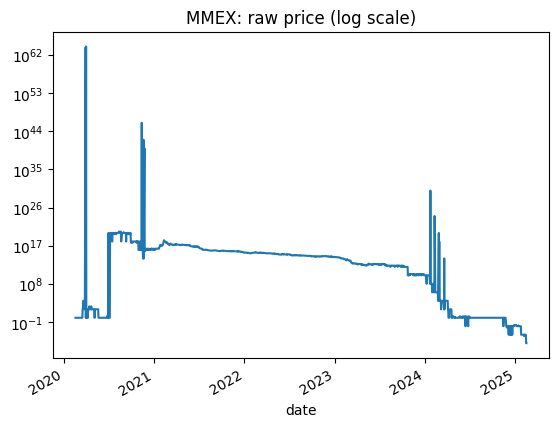

In [9]:
# What does such an error look like?
bad = prices.loc[prices["close"].idxmax(), "symbol"]
prices[prices["symbol"] == bad].set_index("date")["close"].plot(logy=True, title=f"{bad}: raw price (log scale)")

**Decisions for rows:** drop missing prices, duplicate days and impossible prices. With 57 million rows, removing a few thousand costs nothing.

In [10]:
before = len(prices)
prices = (prices.dropna(subset=["close"])
                .drop_duplicates(["symbol", "date"])
                .query("0 < close < 1e9")
                .sort_values(["symbol", "date"]))
prices["ret"] = prices.groupby("symbol", observed=True)["close"].pct_change()   # daily return
print(f"{before:,} -> {len(prices):,} rows")

57,561,149 -> 57,488,125 rows


Now quality **per symbol**. We will model 2023 → 2024, so a symbol must be clean in those two years:

In [11]:
recent = prices[prices["date"] >= "2023-01-01"]
quality = recent.groupby("symbol", observed=True).agg(
    first=("date", "min"),
    last=("date", "max"),
    days=("date", "size"),
    zero_volume=("volume", lambda v: (v == 0).mean()),
    max_move=("ret", lambda r: r.abs().max()),
    volatility=("ret", "std"),
)
quality.describe()

,first,last,days,zero_volume,max_move,volatility
count,51474,51474,51474.00,5.15e+04,5.15e+04,5.15e+04
mean,2023-01-20 09:39:00.272759,2025-02-11 15:21:18.610560,498.13,1.67e-01,6.81e+14,6.23e+13
min,2023-01-01 00:00:00,2023-02-01 00:00:00,1.00,0.00e+00,0.00e+00,0.00e+00
25%,2023-01-02 00:00:00,2025-02-14 00:00:00,510.00,0.00e+00,7.91e-02,1.40e-02
50%,2023-01-03 00:00:00,2025-02-14 00:00:00,528.00,1.88e-03,1.41e-01,2.44e-02
75%,2023-01-03 00:00:00,2025-02-14 00:00:00,532.00,1.40e-01,2.70e-01,3.89e-02
max,2024-12-13 00:00:00,2025-02-18 00:00:00,653.00,1.00e+00,3.17e+19,3.05e+18
std,NaN,NaN,81.38,3.12e-01,1.40e+17,1.35e+16


In [12]:
sym = quality.index.astype(str)
checks = pd.DataFrame({
    "full 2023+2024":        (quality["first"] <= "2023-01-06") & (quality["last"] >= "2024-12-27") & (quality["days"] >= 400),
    "traded (<10% no volume)": quality["zero_volume"] < 0.1,
    "no jump > 75% in a day":  quality["max_move"] < 0.75,         # mostly unadjusted splits / data errors
    "price moves at all":      quality["volatility"] > 0.001,
    "not a fund":              ~(sym.str.match(r"^[A-Z]{4}X$") | sym.str.startswith("0P")),   # US mutual funds, Morningstar funds
}, index=quality.index)
print(checks.mean().map("{:.0%}".format))
ok = checks.all(axis=1)
print(f"\n{ok.sum():,} of {len(ok):,} symbols pass all checks")

full 2023+2024             87%
traded (<10% no volume)    73%
no jump > 75% in a day     90%
price moves at all         99%
not a fund                 94%
dtype: str

32,507 of 51,474 symbols pass all checks


One more thing **only domain knowledge** finds: many companies are listed several times. Frankfurt, Stuttgart, Berlin … trade copies of stocks from all over the world, and every Indian company is listed on both NSE (`.NS`) and BSE (`.BO`). If we keep the copies, the same company can end up in train *and* test. We keep each company's home exchange only, and map the exchange to a region (like `origin` in Auto MPG).

In [13]:
REGION = {
    **dict.fromkeys(["US", "TO", "V", "CN", "MX", "SA", "BA", "SN"], "Americas"),
    **dict.fromkeys(["L", "DE", "PA", "AS", "BR", "MI", "MC", "LS", "SW", "VI", "ST", "OL", "CO", "HE",
                     "IC", "IR", "WA", "PR", "BD", "AT", "IS", "ME"], "Europe"),
    **dict.fromkeys(["T", "HK", "SS", "SZ", "KS", "KQ", "TW", "TWO", "NS", "SI", "JK", "BK", "KL",
                     "AX", "NZ"], "Asia-Pacific"),
    **dict.fromkeys(["JO", "SR", "TA", "QA", "AE", "KW"], "Middle East & Africa"),
}   # not listed = secondary venue (F, SG, BE, DU, HM, IL, NE, BO, ...)

exchange = pd.Series(sym.str.extract(r"\.([A-Z]+)$")[0].fillna("US").values, index=quality.index)
region = exchange.map(REGION)
universe = quality.index[ok & region.notna()]

prices = prices[prices["symbol"].isin(universe)]
prices["symbol"] = prices["symbol"].cat.remove_unused_categories()
print(f"{len(universe):,} stocks, {len(prices):,} rows")
region[universe].value_counts()

30,358 stocks, 36,185,130 rows


Asia-Pacific            13983
Americas                 9075
Europe                   6603
Middle East & Africa      697
Name: count, dtype: int64

A last check that needs domain knowledge: **when** do exchanges trade? Monday to Friday, except in the Middle East (Sunday to Thursday).

In [14]:
day = prices["date"].dt.day_name()
weekend = prices["date"].dt.dayofweek >= 5
pd.crosstab(prices.loc[weekend, "symbol"].map(region), day[weekend])

date,Saturday,Sunday
symbol,,
Americas,15,0
Asia-Pacific,2912,52264
Europe,314,1109
Middle East & Africa,165,65509


In [15]:
# Asian stocks on a Sunday? Those rows are errors. Drop them and recompute the daily returns.
wrong_day = weekend & (prices["symbol"].map(region) != "Middle East & Africa").to_numpy()
prices = prices[~wrong_day].copy()
prices["ret"] = prices.groupby("symbol", observed=True)["close"].pct_change()
print(f"dropped {wrong_day.sum():,} weekend rows")

dropped 56,614 weekend rows


### 3 · Explore: answer questions with data
So far: long format, one row per (symbol, day). For time series, **wide format** is handier: one column per stock, one row per day.

In [16]:
close = prices.pivot(index="date", columns="symbol", values="close")
ret = prices.pivot(index="date", columns="symbol", values="ret")
volume = prices.pivot(index="date", columns="symbol", values="volume")
region = region[close.columns]
close.shape

(1724, 30358)

<Axes: xlabel='date'>

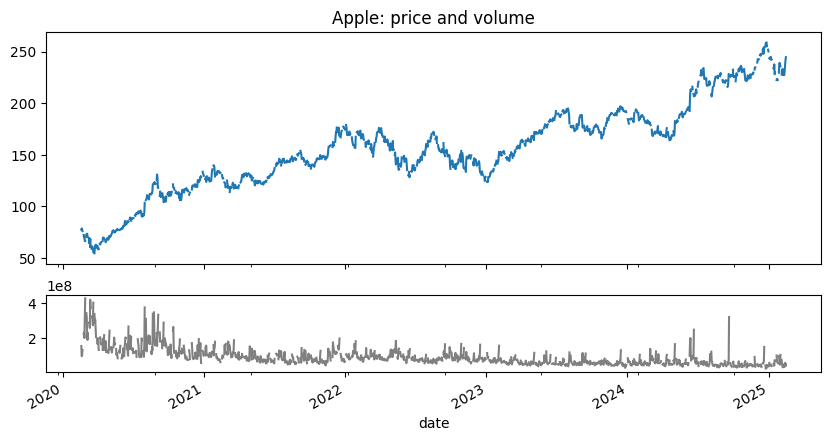

In [17]:
# Q1: What does a single stock look like?
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, height_ratios=[3, 1])
close["AAPL"].plot(ax=ax1, title="Apple: price and volume")
volume["AAPL"].plot(ax=ax2, color="grey")

**Technical analysis** describes a price series with indicators that traders watch. The library `ta` computes them from a pandas Series:
- **SMA 50 / SMA 200**: moving averages of the last 50/200 days (trend). SMA 50 above SMA 200 = uptrend.
- **Bollinger bands**: SMA 20 ± 2 standard deviations. Wide bands = nervous market.
- **RSI** (relative strength index, 0–100): share of recent gains vs. losses. Above 70 "overbought", below 30 "oversold".

Text(0, 0.5, 'RSI 14')

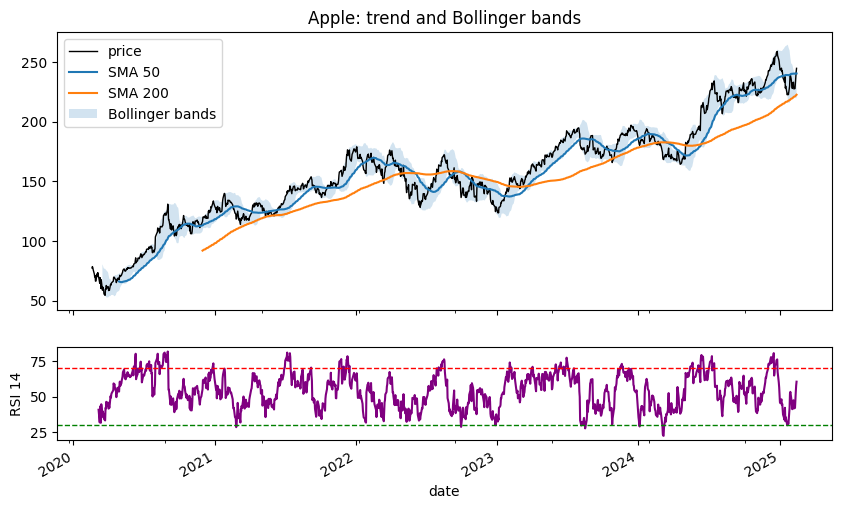

In [18]:
# Q1b: Apple through the eyes of a technical analyst
c = close["AAPL"].dropna()
bb = ta.volatility.BollingerBands(c, window=20, window_dev=2)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[3, 1])
c.plot(ax=ax1, label="price", color="black", lw=1)
ta.trend.sma_indicator(c, 50).plot(ax=ax1, label="SMA 50")
ta.trend.sma_indicator(c, 200).plot(ax=ax1, label="SMA 200")
ax1.fill_between(c.index, bb.bollinger_lband(), bb.bollinger_hband(), alpha=0.2, label="Bollinger bands")
ax1.legend(); ax1.set_title("Apple: trend and Bollinger bands")
ta.momentum.rsi(c, window=14).plot(ax=ax2, color="purple")
ax2.axhline(70, color="red", ls="--", lw=1); ax2.axhline(30, color="green", ls="--", lw=1)
ax2.set_ylabel("RSI 14")

<Axes: title={'center': 'Growth of 100 (log scale)'}, xlabel='date'>

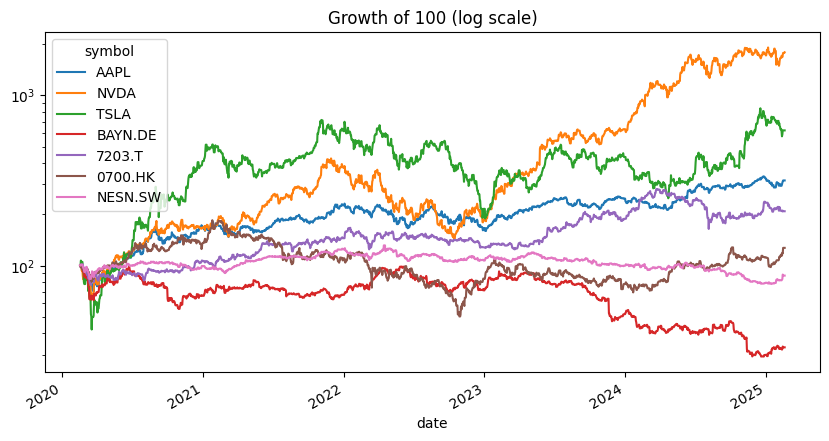

In [19]:
# Q2: How did well-known stocks do? Normalise to 100 at the start to compare different currencies
picks = ["AAPL", "NVDA", "TSLA", "BAYN.DE", "7203.T", "0700.HK", "NESN.SW"]
norm = close[picks].ffill()
(100 * norm / norm.bfill().iloc[0]).plot(logy=True, figsize=(10, 5), title="Growth of 100 (log scale)")

<Axes: title={'center': 'The median stock per region (19 Feb 2020 = 100)'}, xlabel='date'>

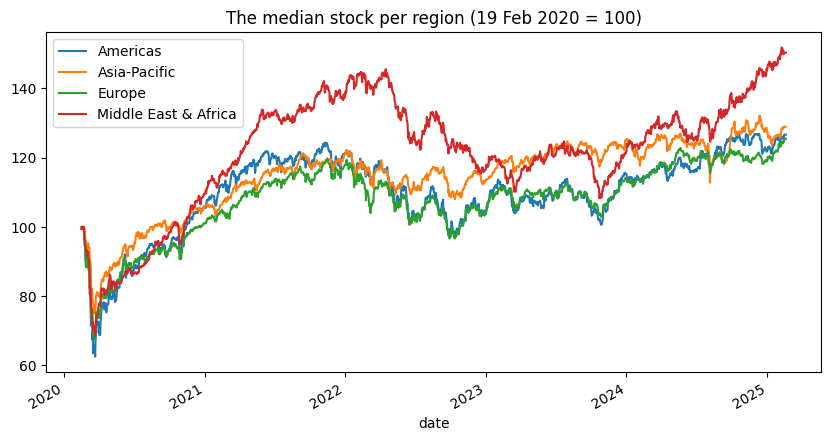

In [20]:
# Q3: How did the typical stock do? Every stock = 100 on 19 Feb 2020, then the median per region
start = close.loc[:"2020-02-19"].ffill().iloc[-1]          # stocks listed later: NaN -> left out
growth = 100 * close.ffill() / start
growth.T.groupby(region).median().T.plot(figsize=(10, 5), title="The median stock per region (19 Feb 2020 = 100)")

COVID crash (March 2020), the boom of 2021, the interest-rate shock of 2022: all visible. Why the median, not the mean? Our quality checks only covered 2023–2024; earlier years still contain a few broken prices, and a single +10⁶⁰ % day destroys a mean. One line for thousands of stocks: that's what aggregation over mass data gives you.

<Axes: title={'center': 'Market volatility'}, xlabel='date'>

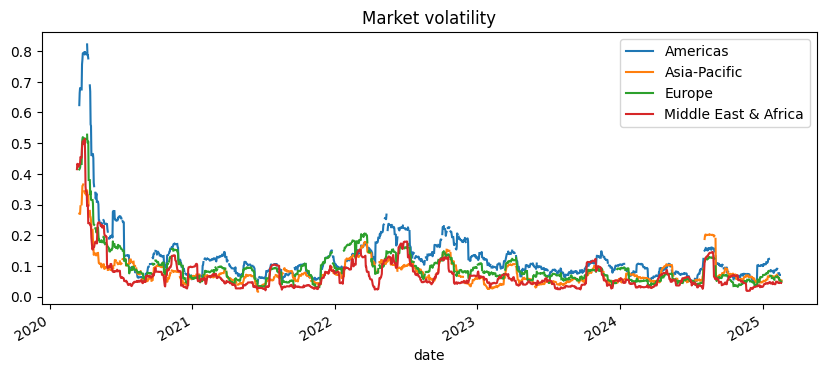

In [21]:
# Q4: When was the market nervous? Median daily return per region = "the market", then its rolling 1-month volatility
traded = ret.notna().T.groupby(region).sum().T                   # how many stocks traded that day?
market = ret.T.groupby(region).median().T.where(traded >= 50)    # holidays: too few stocks -> no value
market.apply(lambda s: s.dropna().rolling(21).std() * np.sqrt(252)).plot(figsize=(10, 4), title="Market volatility")

22,039,908 daily returns


Text(0.5, 1.0, 'Fat tails: extreme days are far more common than a bell curve says')

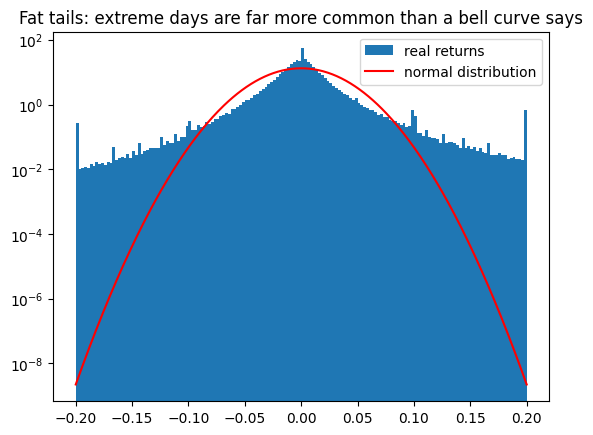

In [22]:
# Q5: Are daily returns normally distributed?
r = ret.loc["2023":"2024"].stack()
print(f"{len(r):,} daily returns")
bins = np.linspace(-0.2, 0.2, 161)
plt.hist(r.clip(-0.2, 0.2), bins=bins, density=True, log=True, label="real returns")
x = np.linspace(-0.2, 0.2, 400)
plt.plot(x, np.exp(-x**2 / (2 * r.var())) / np.sqrt(2 * np.pi * r.var()), "r", label="normal distribution")
plt.legend(); plt.title("Fat tails: extreme days are far more common than a bell curve says")

In [23]:
# Q6: Which region had the best years? (median stock)
yearly = close.resample("YE").last().pct_change(fill_method=None).iloc[1:-1]   # 2021-2024 (2020 and 2025 incomplete)
yearly.index = yearly.index.year
(100 * yearly.T.groupby(region).median()).round(1)        # in %

date,2021,2022,2023,2024
Americas,13.4,-17.3,10.2,6.4
Asia-Pacific,11.9,-10.2,7.5,0.6
Europe,18.1,-14.2,8.0,5.3
Middle East & Africa,27.0,-19.4,7.2,17.5


Median, not mean: a few stocks with +1,000 % would pull the mean up. And careful: returns are in **local currency**. Turkey's or Argentina's high returns are partly inflation, not great companies.
## Part B · Data scientist
### 4 · Feature generation: from 57 million rows to one row per stock
Auto MPG came with features. Here we **generate** them from the time series. Rule: features may only use data **up to 31 Dec 2023**; the target is 2024. Anything from 2024 in a feature = leakage.

In [24]:
A = np.sqrt(252)                                  # daily -> annualised volatility
def price_on(day):                                # last known price on that day
    return close.loc[:day].ffill().iloc[-1]

p_end = price_on("2023-12-31")
r23 = ret.loc["2023"]
c23 = close.loc["2023"]
v23 = volume.loc["2023"]

feat = pd.DataFrame(index=close.columns)
feat["region"] = region
feat["price_2023"] = p_end                                         # local currency!

# Momentum and risk over different horizons
for name, start in [("1m", "2023-12-01"), ("3m", "2023-10-01"), ("6m", "2023-07-01"), ("12m", "2023-01-01")]:
    feat[f"return_{name}"] = p_end / price_on(pd.Timestamp(start) - pd.Timedelta(days=1)) - 1
    feat[f"volatility_{name}"] = ret.loc[start:"2023-12-31"].std() * A

# Shape of the year
feat["max_drawdown_12m"] = (c23 / c23.cummax() - 1).min()           # worst fall from a previous high
feat["dist_to_high_12m"] = p_end / c23.max() - 1                    # how far below the 2023 high
feat["up_days_12m"] = (r23 > 0).sum() / r23.notna().sum()
feat["skew_12m"] = r23.skew()                                       # more big up- or down-days?
feat["kurtosis_12m"] = r23.kurt()                                   # how fat are the tails?
feat["autocorr_12m"] = r23.apply(lambda s: s.autocorr())            # does today predict tomorrow?

# Relation to the market of its region
m = market.loc["2023", region.values].set_axis(r23.columns, axis=1)
feat["beta_12m"] = ((r23 * m).mean() - r23.mean() * m.mean()) / m.var(ddof=0)
feat["market_corr_12m"] = r23.corrwith(m)

# Trading activity
feat["log_volume_12m"] = np.log10(v23.median() + 1)                 # 10 .. 1 bn shares -> 1 .. 9
feat["volume_trend"] = volume.loc["2023-10":"2023-12"].mean() / v23.mean()

# History
peak = price_on("2020-02-19")
listed_before = close.apply(lambda s: s.first_valid_index()) <= pd.Timestamp("2020-02-19")
feat["covid_crash"] = (close.loc["2020-02-20":"2020-04-30"].min() / peak - 1).where(listed_before)

# Targets: what happened in 2024
feat["volatility_2024"] = ret.loc["2024"].std() * A
feat["return_2024"] = price_on("2024-12-31") / p_end - 1

print(feat.shape)
feat.head()

(30358, 23)


,region,price_2023,return_1m,volatility_1m,return_3m,volatility_3m,return_6m,volatility_6m,return_12m,volatility_12m,...,skew_12m,kurtosis_12m,autocorr_12m,beta_12m,market_corr_12m,log_volume_12m,volume_trend,covid_crash,volatility_2024,return_2024
symbol,,,,,,,,,,,,,,,,,,,,,
000001.SZ,Asia-Pacific,8.58,-3.05e-02,0.21,-0.16,0.17,-0.16,0.19,-0.27,0.22,...,0.88,1.88,-0.01,1.38,0.39,7.92,0.89,-0.20,0.26,0.36
000002.SZ,Asia-Pacific,10.46,-8.57e-02,0.29,-0.20,0.28,-0.21,0.28,-0.40,0.26,...,1.25,3.64,-0.16,1.36,0.32,7.82,1.01,-0.17,0.46,-0.31
000006.SZ,Asia-Pacific,4.59,-8.64e-03,0.31,0.01,0.42,0.05,0.49,-0.26,0.41,...,0.67,4.59,0.20,1.25,0.19,7.34,0.78,-0.09,0.60,0.59
000007.SZ,Asia-Pacific,4.87,-5.07e-02,0.19,0.08,0.32,0.09,0.31,-0.37,0.36,...,-0.30,3.06,0.36,0.26,0.05,6.41,0.62,-0.04,0.48,0.44
000008.SZ,Asia-Pacific,2.36,-4.07e-02,0.18,-0.03,0.17,0.00,0.19,0.03,0.21,...,0.69,1.83,0.05,1.27,0.38,7.30,0.88,-0.07,0.54,0.23


**Technical indicators as features.** `ta` works on one Series at a time, so we loop over 30,000 stocks (about a minute). Only data up to end of 2023, the last value of each indicator is the feature. Prices are divided out, so the features are comparable across currencies.

In [25]:
def ta_features(s):
    s = s.dropna()                                   # each exchange has its own holidays
    bb = ta.volatility.BollingerBands(s, window=20, window_dev=2)
    sma50, sma200 = ta.trend.sma_indicator(s, 50), ta.trend.sma_indicator(s, 200)
    return pd.Series({
        "rsi_14":     ta.momentum.rsi(s, window=14).iloc[-1],
        "macd_diff":  ta.trend.macd_diff(s).iloc[-1] / s.iloc[-1],     # MACD relative to price
        "bb_width":   bb.bollinger_wband().iloc[-1],                   # band width in % of SMA 20
        "bb_pband":   bb.bollinger_pband().iloc[-1],                   # 0 = lower band, 1 = upper band
        "sma_50_200": sma50.iloc[-1] / sma200.iloc[-1] - 1,            # > 0 = uptrend
    })

start = time.time()
ta_feat = close.loc["2022-01":"2023-12"].apply(ta_features).T          # 2022 = warm-up for SMA 200
print(f"{len(ta_feat):,} stocks in {time.time() - start:.0f} s")
ta_cols = list(ta_feat.columns)
feat = feat.join(ta_feat)
ta_feat.describe()

30,358 stocks in 28 s


,rsi_14,macd_diff,bb_width,bb_pband,sma_50_200
count,3.04e+04,3.04e+04,30358.00,30345.00,3.04e+04
mean,5.71e+01,1.29e-03,14.57,0.65,-1.13e-02
std,1.16e+01,8.93e-03,13.94,0.27,1.51e-01
min,3.64e-12,-3.00e-01,0.00,-0.53,-9.62e-01
25%,4.89e+01,-1.70e-03,6.46,0.45,-7.41e-02
50%,5.69e+01,6.65e-04,10.63,0.70,-1.09e-03
75%,6.57e+01,3.89e-03,17.72,0.83,4.90e-02
max,1.00e+02,4.01e-01,246.48,1.59,1.53e+00


In [26]:
feat.describe().T

,count,mean,std,min,25%,50%,75%,max
price_2023,30358.0,1.85e+03,1.52e+04,3.00e-04,8.48e+00,2.96e+01,1.70e+02,760000.00
return_1m,30358.0,4.05e-02,1.30e-01,-8.00e-01,-1.96e-02,2.86e-02,7.85e-02,2.58
volatility_1m,30352.0,3.50e-01,3.09e-01,0.00e+00,1.67e-01,2.66e-01,4.26e-01,4.46
return_3m,30358.0,5.65e-02,2.27e-01,-9.61e-01,-4.63e-02,4.40e-02,1.27e-01,5.66
volatility_3m,30357.0,3.80e-01,2.82e-01,0.00e+00,2.04e-01,3.08e-01,4.65e-01,3.54
return_6m,30358.0,4.59e-02,3.15e-01,-9.65e-01,-9.41e-02,3.07e-02,1.25e-01,8.67
volatility_6m,30358.0,3.70e-01,2.61e-01,0.00e+00,2.03e-01,3.06e-01,4.57e-01,3.26
return_12m,30351.0,1.57e-01,5.74e-01,-9.99e-01,-9.43e-02,8.52e-02,2.76e-01,27.79
volatility_12m,30358.0,3.79e-01,2.51e-01,0.00e+00,2.16e-01,3.22e-01,4.67e-01,3.29
max_drawdown_12m,30358.0,-3.01e-01,1.84e-01,-9.99e-01,-4.02e-01,-2.60e-01,-1.61e-01,0.00


In [27]:
feat.isnull().sum()[lambda s: s > 0]      # covid_crash: listed after Feb 2020. Will be imputed in the pipeline.

volatility_1m         6
volatility_3m         1
return_12m            7
autocorr_12m          1
market_corr_12m       1
volume_trend          1
covid_crash        4688
bb_pband             13
sma_50_200            1
dtype: int64

Text(0.5, 1.0, 'Correlation with volatility_2024')

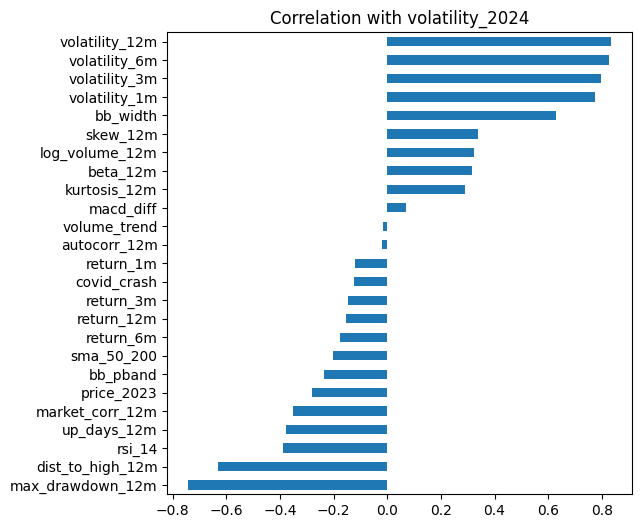

In [28]:
# Which features move together with the target? (Spearman: rank-based, robust to outliers)
feat.drop(columns="region").corr(method="spearman")["volatility_2024"].drop(["volatility_2024", "return_2024"]).sort_values().plot(kind="barh", figsize=(6, 6))
plt.title("Correlation with volatility_2024")

Text(0.5, 1.0, 'Volatile stocks stay volatile')

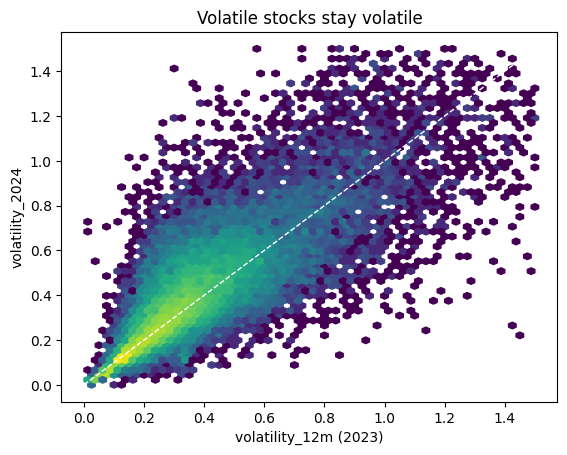

In [29]:
plt.hexbin(feat["volatility_12m"], feat["volatility_2024"], gridsize=60, extent=(0, 1.5, 0, 1.5), bins="log", cmap="viridis")
plt.plot([0, 1.5], [0, 1.5], "w--", lw=1)
plt.xlabel("volatility_12m (2023)"); plt.ylabel("volatility_2024")
plt.title("Volatile stocks stay volatile")

A scatter plot of 30,000 points is just a blob. A **hexbin** counts points per cell: better for mass data.

Careful: correlation is not causation. High volatility in 2023 doesn't *cause* volatility in 2024: the business (biotech start-up vs. utility) causes both.
### 5 · Split first, then touch the data

In [30]:
from sklearn.model_selection import train_test_split

X = feat.drop(columns=["volatility_2024", "return_2024"])     # BOTH 2024 columns are the future -> never a feature
y = feat["volatility_2024"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "train /", len(X_test), "test")

24286 train / 6072 test


In [31]:
# Why split first? Any statistic computed on ALL data leaks the test set into training.
print("median covid_crash, all data :", X["covid_crash"].median())
print("median covid_crash, train only:", X_train["covid_crash"].median())

median covid_crash, all data : -0.3458138963238166
median covid_crash, train only: -0.34568584269491803


### 6 · Scaling and pipelines
Why scale? Gradient descent: `price_2023` goes up to hundreds of thousands (yen, won, rupiah …), `up_days_12m` lies between 0 and 1. One learning rate can't fit both.

In [32]:
from sklearn.linear_model import SGDRegressor

num = [c for c in X.columns if c != "region"]
Xn = X_train[num].fillna(X_train[num].median())

sgd = SGDRegressor(max_iter=1000, random_state=0).fit(Xn, y_train)
print("unscaled, first weights:", sgd.coef_[:3])     # explodes

unscaled, first weights: [-2.39009149e+13 -5.50360694e+10 -1.45460048e+11]


In [33]:
from sklearn.preprocessing import StandardScaler

Xs = StandardScaler().fit_transform(Xn)
sgd = SGDRegressor(max_iter=1000, random_state=0).fit(Xs, y_train)
print("scaled, first weights:", sgd.coef_[:3].round(2))

scaled, first weights: [-0.   -0.01  0.03]


In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric = Pipeline([
    ("impute", SimpleImputer(strategy="median")),   # fit on train only, automatically
    ("scale", StandardScaler()),
])

### 7 · Finally: train

In [35]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

def evaluate(name, model, cols=num, y_train=y_train, y_test=y_test):
    pre = ColumnTransformer([("num", numeric, cols),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), ["region"])])
    pipe = Pipeline([("prep", pre), ("model", model)]).fit(X_train, y_train)
    pred = pipe.predict(X_test)
    return {"model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "R2": r2_score(y_test, pred)}, pipe

models = [
    ("Baseline: always the mean", DummyRegressor(strategy="mean"), num),
    ("Linear: only volatility_12m", LinearRegression(), ["volatility_12m"]),
    ("Linear: all features", LinearRegression(), num),
    ("Random forest: without TA", RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1),
     [c for c in num if c not in ta_cols]),
    ("Random forest", RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1), num),
]
results = []
for name, model, cols in models:
    r, pipe = evaluate(name, model, cols)
    results.append(r)
pd.DataFrame(results).round(2)

,model,MAE,R2
0,Baseline: always the mean,0.20,-0.00
1,Linear: only volatility_12m,0.09,0.73
2,Linear: all features,0.09,0.76
3,Random forest: without TA,0.08,0.80
4,Random forest,0.08,0.80


MAE 0.08 means: we predict next year's volatility to within about ±8 percentage points on average (baseline: ±20).

The technical indicators add **nothing**. `bb_width` correlates strongly with the target, but it is just another volatility measure: the model already knows that from `volatility_12m`. More features ≠ better model; new features must carry *new* information.

Text(0.5, 1.0, 'What the random forest relies on')

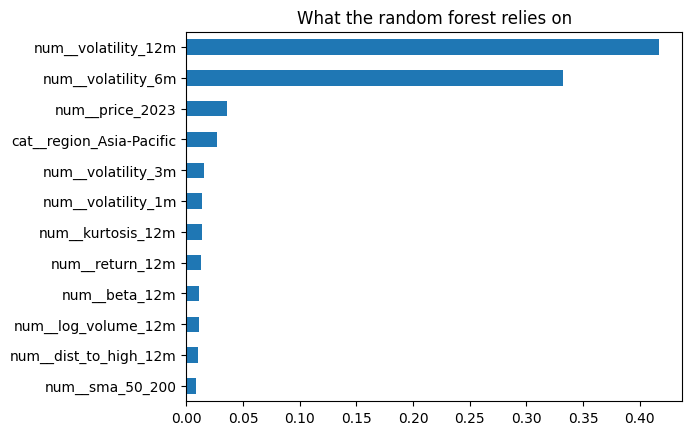

In [36]:
rf = pipe.named_steps["model"]
names = pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.feature_importances_, index=names).sort_values()
imp.tail(12).plot(kind="barh")
plt.title("What the random forest relies on")

### 8 · Many models at once: GridSearchCV
Which model, which settings? Instead of trying by hand, `GridSearchCV` tries every combination. Each one is scored by **cross-validation on the training data**: train is split into 3 parts, the model trains on 2 and is scored on the third, three times. The test set stays untouched until the very end.

In [37]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

preprocess = ColumnTransformer([("num", numeric, num),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), ["region"])])
pipe = Pipeline([("prep", preprocess), ("model", Ridge())])

param_grid = [   # the model itself is a parameter, too
    {"model": [Ridge()],
     "model__alpha": [0.1, 10, 1000]},                       # strength of regularisation
    {"model": [KNeighborsRegressor()],
     "model__n_neighbors": [5, 20, 50]},                     # how many similar stocks to average
    {"model": [RandomForestRegressor(n_estimators=100, random_state=42)],
     "model__min_samples_leaf": [1, 5, 20]},                 # how small a leaf may get
    {"model": [HistGradientBoostingRegressor(random_state=42)],
     "model__learning_rate": [0.03, 0.1],
     "model__max_leaf_nodes": [15, 63]},
]
search = GridSearchCV(pipe, param_grid, cv=3, scoring="neg_mean_absolute_error", n_jobs=-1)

start = time.time()
search.fit(X_train, y_train)
print(f"{len(search.cv_results_['params'])} combinations x 3 folds in {time.time() - start:.0f} s")

13 combinations x 3 folds in 47 s


In [38]:
cv = pd.DataFrame(search.cv_results_)
cv["model"] = cv["param_model"].map(lambda m: type(m).__name__)
cv["settings"] = cv["params"].map(lambda p: ", ".join(f"{k.split('__')[1]}={v}" for k, v in p.items() if k != "model"))
cv["MAE (CV)"] = -cv["mean_test_score"]
cv["fit time (s)"] = cv["mean_fit_time"]
with pd.option_context("display.precision", 3):
    display(cv.sort_values("MAE (CV)")[["model", "settings", "MAE (CV)", "fit time (s)"]])

,model,settings,MAE (CV),fit time (s)
7,RandomForestRegressor,min_samples_leaf=5,0.080,16.682
6,RandomForestRegressor,min_samples_leaf=1,0.080,19.858
12,HistGradientBoostingRegressor,"learning_rate=0.1, max_leaf_nodes=63",0.080,0.457
8,RandomForestRegressor,min_samples_leaf=20,0.081,13.690
11,HistGradientBoostingRegressor,"learning_rate=0.1, max_leaf_nodes=15",0.082,0.289
10,HistGradientBoostingRegressor,"learning_rate=0.03, max_leaf_nodes=63",0.083,0.639
4,KNeighborsRegressor,n_neighbors=20,0.085,0.043
9,HistGradientBoostingRegressor,"learning_rate=0.03, max_leaf_nodes=15",0.086,0.311
5,KNeighborsRegressor,n_neighbors=50,0.087,0.042
3,KNeighborsRegressor,n_neighbors=5,0.088,0.048


Text(0.5, 1.0, 'Best setting per model')

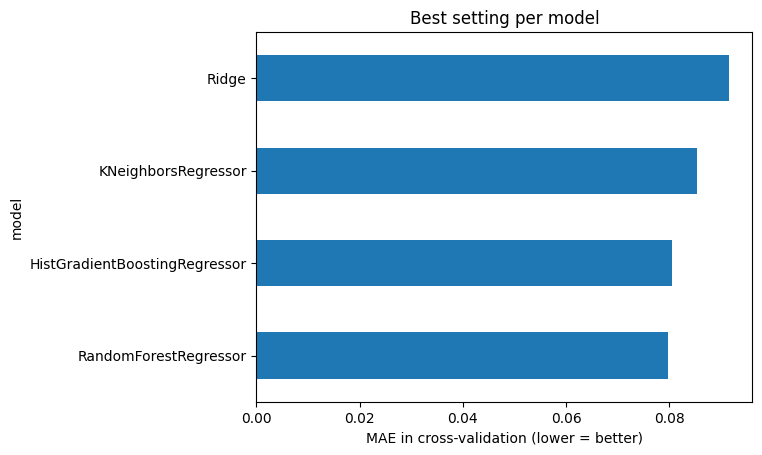

In [39]:
best_per_model = cv.groupby("model")["MAE (CV)"].min().sort_values()
best_per_model.plot(kind="barh")
plt.xlabel("MAE in cross-validation (lower = better)")
plt.title("Best setting per model")

In [40]:
# Only now, once: the winner on the test set
print("best:", search.best_params_)
pred = search.best_estimator_.predict(X_test)
print(f"test MAE {mean_absolute_error(y_test, pred):.3f}, R2 {r2_score(y_test, pred):.2f}")

best: {'model': RandomForestRegressor(random_state=42), 'model__min_samples_leaf': 5}
test MAE 0.076, R2 0.80


### 9 · And now the question everybody asks: can we predict the **return**?
Same features, same pipeline, same models. Only the target changes.

In [41]:
yr_train, yr_test = feat.loc[X_train.index, "return_2024"], feat.loc[X_test.index, "return_2024"]

results = []
for name, model, cols in models:
    r, _ = evaluate(name, model, cols, y_train=yr_train, y_test=yr_test)
    results.append(r)
pd.DataFrame(results).round(2)

,model,MAE,R2
0,Baseline: always the mean,0.29,-0.00
1,Linear: only volatility_12m,0.29,0.00
2,Linear: all features,0.28,0.02
3,Random forest: without TA,0.27,0.04
4,Random forest,0.27,0.05


Almost nothing, even with 30,000 stocks and 25 features, technical indicators included. *How much* a stock will move is predictable; *in which direction* it will move is (nearly) not. If last year's numbers predicted returns, everybody would trade on it, and the effect would vanish (efficient markets).

A good data scientist reports this honestly instead of tuning until the test set looks good.

### 10 · Outlook: a neural network with PyTorch
Same data, same preprocessing, but now we build the model ourselves: layers, loss, optimiser, training loop. scikit-learn hides all of this inside `.fit()`.

In [42]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Preprocessing as before: impute + scale + one-hot. Fit on train only.
prep = ColumnTransformer([("num", numeric, num),
                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["region"])])
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=0)   # val: watch training
to_tensor = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)

Xt_fit, Xt_val, Xt_test = to_tensor(prep.fit_transform(X_fit)), to_tensor(prep.transform(X_val)), to_tensor(prep.transform(X_test))
yt_fit, yt_val = to_tensor(y_fit).unsqueeze(1), to_tensor(y_val).unsqueeze(1)
print("input features:", Xt_fit.shape[1])

input features: 29


<Axes: title={'center': 'Training curve'}, xlabel='epoch', ylabel='MSE'>

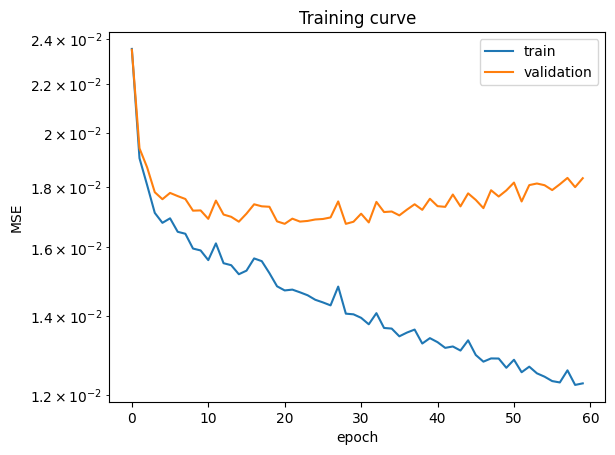

In [43]:
torch.manual_seed(0)
net = nn.Sequential(                 # 29 inputs -> 64 -> 32 -> 1 output (the predicted volatility)
    nn.Linear(Xt_fit.shape[1], 64), nn.ReLU(),
    nn.Linear(64, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
batches = DataLoader(TensorDataset(Xt_fit, yt_fit), batch_size=256, shuffle=True)

history = []
for epoch in range(60):
    net.train()
    for xb, yb in batches:               # one step of gradient descent per mini-batch
        optimizer.zero_grad()
        loss = loss_fn(net(xb), yb)
        loss.backward()                  # compute gradients
        optimizer.step()                 # update weights
    net.eval()
    with torch.no_grad():
        history.append({"train": loss_fn(net(Xt_fit), yt_fit).item(),
                        "validation": loss_fn(net(Xt_val), yt_val).item()})

pd.DataFrame(history).plot(logy=True, xlabel="epoch", ylabel="MSE", title="Training curve")

Train loss keeps falling; the validation loss stops falling after about 20 epochs and then slowly rises: the network starts to memorise the training data, **overfitting**. (Fix: stop early, or regularise, e.g. with dropout.)

In [44]:
with torch.no_grad():
    pred = net(Xt_test).squeeze().numpy()
print(f"neural network: test MAE {mean_absolute_error(y_test, pred):.3f}, R2 {r2_score(y_test, pred):.2f}")

neural network: test MAE 0.080, R2 0.79


On tabular data with a few dozen features, a neural network is usually **no better than a random forest or gradient boosting**, and needs more code and more tuning. Neural networks shine on images, text and audio, where there are no hand-made features.

**Next session (chapter 04 Testing):** Is one random split enough? Here all rows come from the same years: a real forecast would train on 2022→2023 and test on 2023→2024. Cross-validation, overfitting, and what MAE = 0.08 actually means.